In [1]:
import sys  # lets us change where Python looks for imports
sys.path.append("..")  # add the project root so "src" can be imported from the notebook
from src.data import load_raw, make_weekly_table  # import your two Day 1 functions

raw = load_raw("../data/superstore.csv")  # load the raw csv (path goes up one folder from notebooks)
weekly = make_weekly_table(raw)  # build the weekly table with all sub-categories

print(weekly.shape)  # show how many rows and columns the table has
print(weekly.columns.tolist())  # show the column names
print(weekly.head())  # show the first 5 rows

(209, 9)
['Phones', 'Chairs', 'Storage', 'Binders', 'Accessories', 'Appliances', 'Furnishings', 'Paper', 'Tables']
Sub-Category   Phones   Chairs   Storage  Binders  Accessories  Appliances  \
2015-01-04       0.00     0.00   272.736    3.540         0.00       0.000   
2015-01-11    1147.94  2573.82     0.000  620.410        31.20       0.000   
2015-01-18     124.20   545.94  1898.430   27.666       796.69      64.864   
2015-01-25     699.93  1067.94    80.560  148.284         0.00     247.716   
2015-02-01     343.33     0.00   777.090   14.608       468.90       0.000   

Sub-Category  Furnishings    Paper  Tables  
2015-01-04          0.000   16.448     0.0  
2015-01-11        138.608   25.980     0.0  
2015-01-18        127.104   37.408     0.0  
2015-01-25        345.570  115.504     0.0  
2015-02-01         75.240   46.680   333.0  


In [2]:
%load_ext autoreload
%autoreload 2
from src.features import to_long  # import the new function
long = to_long(weekly)  # convert the wide table to long format
print(long.shape)  # expect (1881, 3): 209 weeks x 9 categories, 3 columns
print(long.head(10))  # show the first 10 rows

(1881, 3)
        date     category   sales
0 2015-01-04  Accessories    0.00
1 2015-01-11  Accessories   31.20
2 2015-01-18  Accessories  796.69
3 2015-01-25  Accessories    0.00
4 2015-02-01  Accessories  468.90
5 2015-02-08  Accessories  115.36
6 2015-02-15  Accessories  474.42
7 2015-02-22  Accessories   62.31
8 2015-03-01  Accessories    0.00
9 2015-03-08  Accessories  479.97


In [3]:
from src.features import add_lags  # import the new function
feat = add_lags(long)  # add lag_1, lag_2, lag_4, lag_8, lag_52 columns
print(feat.shape)  # expect (1881, 8): 3 original columns + 5 lag columns
print(feat[["date", "category", "sales", "lag_1", "lag_52"]].head(3))  # first weeks: lags should be NaN (no past data yet)
print(feat[["date", "category", "sales", "lag_1", "lag_52"]].iloc[52:55])  # week 53 onward: lag_52 should now have values

(1881, 8)
        date     category   sales  lag_1  lag_52
0 2015-01-04  Accessories    0.00    NaN     NaN
1 2015-01-11  Accessories   31.20    0.0     NaN
2 2015-01-18  Accessories  796.69   31.2     NaN
         date     category     sales     lag_1  lag_52
52 2016-01-03  Accessories  2567.806   560.850    0.00
53 2016-01-10  Accessories     0.000  2567.806   31.20
54 2016-01-17  Accessories    10.384     0.000  796.69


In [5]:
from src.features import add_rolling  # import the new function
feat = add_rolling(feat)  # add roll_mean and roll_std for 4, 8, 12 weeks
print(feat.shape)  # expect (1881, 14): 8 columns + 6 rolling columns
check = feat[["date", "category", "sales", "roll_mean_4"]].iloc[3:7].copy()  # take rows 3 to 6 to check by hand
check["manual_mean_4"] = feat["sales"].iloc[0:7].rolling(4).mean().shift(1).iloc[3:7].values  # compute the same mean by hand from earlier rows
print(check)  # roll_mean_4 and manual_mean_4 should match, row 3 is NaN, row 4 onward has values

(1881, 14)
        date     category   sales  roll_mean_4  manual_mean_4
3 2015-01-25  Accessories    0.00          NaN            NaN
4 2015-02-01  Accessories  468.90     206.9725       206.9725
5 2015-02-08  Accessories  115.36     324.1975       324.1975
6 2015-02-15  Accessories  474.42     345.2375       345.2375


In [6]:
from src.features import add_calendar  # import the new function
feat = add_calendar(feat)  # add week_of_year, month, is_q4
print(feat.shape)  # expect (1881, 17): 14 columns + 3 calendar columns
print(feat[["date", "week_of_year", "month", "is_q4"]].iloc[[0, 40, 48]])  # early Jan (q4=0), Oct (q4=1), Dec (q4=1)

(1881, 17)
         date  week_of_year  month  is_q4
0  2015-01-04             1      1      0
40 2015-10-11            41     10      1
48 2015-12-06            49     12      1


In [7]:
from src.features import build_features, FEATURES  # import the pipeline and feature list
feat = build_features(weekly)  # build everything from the original wide table in one call
print(feat.shape)  # expect (1881, 17)
print(len(FEATURES))  # expect 15 features
print(feat["category"].dtype)  # expect "category"

(1881, 17)
15
category


In [8]:
from src.validation import walk_forward_splits  # Day 2 fold function
from src.models import train_lgbm, recursive_forecast  # the new functions
from src.metrics import mae  # Day 2 metric
train_idx, test_idx = next(walk_forward_splits(len(weekly)))  # take only the first fold
weekly_train = weekly.iloc[train_idx]  # weeks 1 to 169
weekly_test = weekly.iloc[test_idx]  # weeks 170 to 177 (the real answers)
model = train_lgbm(weekly_train)  # train the global model on fold 1
pred = recursive_forecast(model, weekly_train, horizon=len(test_idx))  # forecast 8 weeks ahead
print((pred.index == weekly_test.index).all())  # True means the forecast dates match the test dates
print(pred.round(0).head(3))  # first 3 forecast weeks for all 9 categories
print(mae(weekly_test.values.ravel(), pred.values.ravel()))  # fold 1 MAE across all categories

True
Sub-Category  Phones  Chairs  Storage  Binders  Accessories  Appliances  \
2018-04-01    1019.0  1144.0   1224.0    422.0        138.0       142.0   
2018-04-08    1108.0  1060.0    758.0    568.0        368.0       141.0   
2018-04-15    1206.0   642.0    826.0    857.0        645.0       335.0   

Sub-Category  Furnishings  Paper  Tables  
2018-04-01          287.0  347.0   487.0  
2018-04-08          337.0  368.0   494.0  
2018-04-15          396.0  308.0   933.0  
532.3037274344533


In [9]:
from src.evaluate import evaluate  # the scoring loop
from src.models import global_forecast  # the global model method
res_global = evaluate(weekly, global_forecast, "lgbm_global")  # run all 5 folds (takes a few seconds)
print(res_global.shape)  # expect (45, 7): 5 folds x 9 categories
print(res_global[["mae", "rmse", "smape", "mase"]].mean().round(2))  # averaged like Day 2, comparable to the baselines
print(res_global.groupby("fold")["mae"].mean().round(0))  # MAE per fold, to see which folds are hardest

(45, 7)
mae       867.22
rmse     1132.52
smape      75.92
mase        1.07
dtype: float64
fold
1     532.0
2     668.0
3    1035.0
4    1019.0
5    1082.0
Name: mae, dtype: float64


In [10]:
from src.models import per_category_forecast  # the per-category method
res_per_cat = evaluate(weekly, per_category_forecast, "lgbm_per_category")  # run all 5 folds (9 models per fold, a bit slower)
print(res_per_cat.shape)  # expect (45, 7)
print(res_per_cat[["mae", "rmse", "smape", "mase"]].mean().round(2))  # averaged like Day 2
print(res_per_cat.groupby("fold")["mae"].mean().round(0))  # MAE per fold

(45, 7)
mae       986.14
rmse     1260.29
smape      89.54
mase        1.23
dtype: float64
fold
1     688.0
2     677.0
3    1104.0
4    1156.0
5    1305.0
Name: mae, dtype: float64


In [11]:
import os  # lets us list files in a folder
import pandas as pd  # pandas for reading CSVs
print(os.listdir("../results"))  # show every file in the results folder
for f in os.listdir("../results"):  # loop over those files
    if f.endswith(".csv"):  # only look at CSV files
        df = pd.read_csv(f"../results/{f}")  # read the file
        print(f, df.shape)  # file name and its number of rows and columns
        print(df.head(3))  # first 3 rows, so we can see its layout

['baseline_scores.csv', 'baseline_scores_by_category.csv', 'baseline_scores_by_fold.csv']
baseline_scores.csv (3, 5)
            model       mae      rmse   smape   mase
0    moving_avg_4   987.318  1205.533  82.884  1.229
1  seasonal_naive  1127.138  1460.396  98.482  1.384
2           naive  1133.055  1384.601  91.143  1.452
baseline_scores_by_category.csv (27, 6)
      category           model       mae      rmse    smape   mase
0  Accessories    moving_avg_4   874.097  1022.532   76.087  1.292
1  Accessories           naive  1104.297  1246.965   81.357  1.606
2  Accessories  seasonal_naive  1073.121  1349.364  102.387  1.580
baseline_scores_by_fold.csv (135, 7)
   fold category           model        mae         rmse      smape      mase
0     1   Phones           naive  958.21225  1128.244661  81.053241  0.807689
1     1   Phones  seasonal_naive  791.51300   975.654586  82.252153  0.667177
2     1   Phones    moving_avg_4  850.94900  1027.305812  78.128267  0.717276


In [12]:
metrics = ["mae", "rmse", "smape", "mase"]  # the four score columns
base_fold = pd.read_csv("../results/baseline_scores_by_fold.csv")  # Day 2 scores per fold and category
all_fold = pd.concat([base_fold, res_global, res_per_cat], ignore_index=True)  # stack baselines and both LightGBM versions into one table
all_scores = all_fold.groupby("model")[metrics].mean().sort_values("mae").round(3).reset_index()  # average per model, best MAE first
all_by_cat = all_fold.groupby(["category", "model"])[metrics].mean().round(3).reset_index()  # average per model and category
all_fold.to_csv("../results/all_scores_by_fold.csv", index=False)  # save the detailed table (baseline files stay untouched)
all_scores.to_csv("../results/all_scores.csv", index=False)  # save the main results table
all_by_cat.to_csv("../results/all_scores_by_category.csv", index=False)  # save the per-category table
print(all_scores)  # main table: baselines should show the same numbers as Day 2
print(all_by_cat.pivot(index="category", columns="model", values="mae").round(0))  # MAE per category, one column per model

               model       mae      rmse   smape   mase
0        lgbm_global   867.218  1132.518  75.919  1.066
1  lgbm_per_category   986.142  1260.285  89.542  1.228
2       moving_avg_4   987.318  1205.533  82.884  1.229
3     seasonal_naive  1127.138  1460.396  98.482  1.384
4              naive  1133.055  1384.601  91.143  1.452
model        lgbm_global  lgbm_per_category  moving_avg_4   naive  \
category                                                            
Accessories        850.0              922.0         874.0  1104.0   
Appliances         530.0              717.0         726.0   760.0   
Binders           1182.0             1393.0        1320.0  1162.0   
Chairs            1204.0             1385.0        1602.0  1927.0   
Furnishings        396.0              492.0         541.0   661.0   
Paper              312.0              364.0         345.0   504.0   
Phones            1286.0             1570.0        1275.0  1387.0   
Storage            979.0              979.0

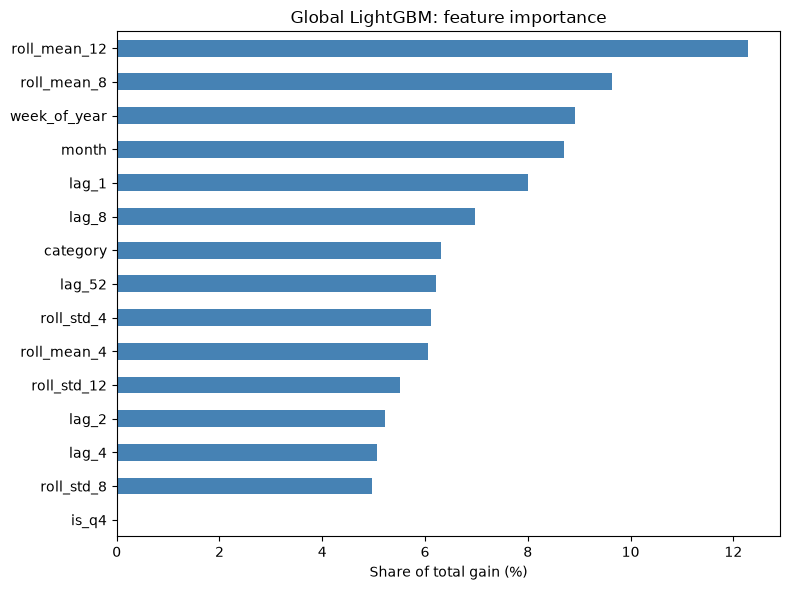

roll_mean_12    12.3
roll_mean_8      9.6
week_of_year     8.9
month            8.7
lag_1            8.0
lag_8            7.0
category         6.3
lag_52           6.2
roll_std_4       6.1
roll_mean_4      6.1
roll_std_12      5.5
lag_2            5.2
lag_4            5.1
roll_std_8       5.0
is_q4            0.0
dtype: float64


In [13]:
import matplotlib.pyplot as plt  # for plotting
from src.features import FEATURES  # the 15 feature names
full_model = train_lgbm(weekly)  # train the global model on all 209 weeks (only for this plot)
gain = full_model.booster_.feature_importance(importance_type="gain")  # total error reduction each feature gave the model
imp = pd.Series(gain, index=FEATURES).sort_values()  # label each value with its feature name, smallest first
imp = imp / imp.sum() * 100  # turn into percentages that add up to 100
fig, ax = plt.subplots(figsize=(8, 6))  # create the figure
imp.plot.barh(ax=ax, color="steelblue")  # horizontal bars, biggest at the top
ax.set_xlabel("Share of total gain (%)")  # x-axis label
ax.set_title("Global LightGBM: feature importance")  # chart title
plt.tight_layout()  # stop labels from being cut off
plt.savefig("../results/feature_importance_global.png", dpi=150)  # save the plot for the README
plt.show()  # display it in the notebook
print(imp.sort_values(ascending=False).round(1))  # the same numbers as a list, biggest first